# Motor Insurance Risk Assessment

## The Impact of Driver Age and Vehicle Age on Claim Frequency, Expected Losses and Insurance Premiums

### Project Overview

This project analyzes real motor insurance data to investigate how driver age and vehicle age influence insurance risk.

The analysis focuses on:
- Claim frequency across different driver age groups.
- Claim frequency based on vehicle age.
- The relationship between driving experience and insurance risk.
- Insurance claim costs and premiums.
- The application of probability, statistics, and mathematical concepts to insurance data.

The project uses Python and Jupyter Notebook for data analysis, mathematical calculations, and visualization.


## Data Source

The data used in this project comes from a motor insurance dataset published as part of a scientific study in 2024.

The dataset contains information about drivers, vehicles, insurance premiums and claims.

Sources:
- [Scientific article – European Actuarial Journal](https://link.springer.com/article/10.1007/s13385-024-00398-0)
- [Motor Insurance Dataset – Mendeley Data](https://doi.org/10.17632/5cxyb5fp4f.2)

In [45]:
import pandas as pd

In [46]:
import matplotlib.pyplot as plt

In [47]:
df = pd.read_csv("data/Motor vehicle insurance data.csv", sep=";")

In [48]:
df.head()

,ID,Date_start_contract,Date_last_renewal,Date_next_renewal,Date_birth,Date_driving_licence,Distribution_channel,Seniority,Policies_in_force,Max_policies,...,Area,Second_driver,Year_matriculation,Power,Cylinder_capacity,Value_vehicle,N_doors,Type_fuel,Length,Weight
0,1,05/11/2015,05/11/2015,05/11/2016,15/04/1956,20/03/1976,0,4,1,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
1,1,05/11/2015,05/11/2016,05/11/2017,15/04/1956,20/03/1976,0,4,1,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
2,1,05/11/2015,05/11/2017,05/11/2018,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
3,1,05/11/2015,05/11/2018,05/11/2019,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
4,2,26/09/2017,26/09/2017,26/09/2018,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190


In [49]:
df.shape


(105555, 30)

In [50]:
df.columns

Index(['ID', 'Date_start_contract', 'Date_last_renewal', 'Date_next_renewal',
       'Date_birth', 'Date_driving_licence', 'Distribution_channel',
       'Seniority', 'Policies_in_force', 'Max_policies', 'Max_products',
       'Lapse', 'Date_lapse', 'Payment', 'Premium', 'Cost_claims_year',
       'N_claims_year', 'N_claims_history', 'R_Claims_history', 'Type_risk',
       'Area', 'Second_driver', 'Year_matriculation', 'Power',
       'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Type_fuel', 'Length',
       'Weight'],
      dtype='str')

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 105555 entries, 0 to 105554
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    105555 non-null  int64  
 1   Date_start_contract   105555 non-null  str    
 2   Date_last_renewal     105555 non-null  str    
 3   Date_next_renewal     105555 non-null  str    
 4   Date_birth            105555 non-null  str    
 5   Date_driving_licence  105555 non-null  str    
 6   Distribution_channel  105555 non-null  int64  
 7   Seniority             105555 non-null  int64  
 8   Policies_in_force     105555 non-null  int64  
 9   Max_policies          105555 non-null  int64  
 10  Max_products          105555 non-null  int64  
 11  Lapse                 105555 non-null  int64  
 12  Date_lapse            35147 non-null   str    
 13  Payment               105555 non-null  int64  
 14  Premium               105555 non-null  float64
 15  Cost_claims

In [52]:
df["Type_risk"].value_counts()

Type_risk
3    82990
2    13212
1     8502
4      851
Name: count, dtype: int64

In [53]:
df["Type_risk"].value_counts()

Type_risk
3    82990
2    13212
1     8502
4      851
Name: count, dtype: int64

In [54]:
df.isnull().sum()

ID                          0
Date_start_contract         0
Date_last_renewal           0
Date_next_renewal           0
Date_birth                  0
Date_driving_licence        0
Distribution_channel        0
Seniority                   0
Policies_in_force           0
Max_policies                0
Max_products                0
Lapse                       0
Date_lapse              70408
Payment                     0
Premium                     0
Cost_claims_year            0
N_claims_year               0
N_claims_history            0
R_Claims_history            0
Type_risk                   0
Area                        0
Second_driver               0
Year_matriculation          0
Power                       0
Cylinder_capacity           0
Value_vehicle               0
N_doors                     0
Type_fuel                1764
Length                  10329
Weight                      0
dtype: int64

In [55]:
df.duplicated().sum()


np.int64(0)

In [56]:
# Calculate driver age at the start of the contract
contract_date = pd.to_datetime(df["Date_start_contract"], format="%d/%m/%Y")
birth_date = pd.to_datetime(df["Date_birth"], format="%d/%m/%Y")

driver_age = (
    contract_date.dt.year
    - birth_date.dt.year
    - (
        (contract_date.dt.month < birth_date.dt.month)
        | (
            (contract_date.dt.month == birth_date.dt.month)
            & (contract_date.dt.day < birth_date.dt.day)
        )
    )
)

driver_age.describe()

count    105555.000000
mean         43.846260
std          12.764041
min          18.000000
25%          34.000000
50%          43.000000
75%          53.000000
max          91.000000
dtype: float64

In [57]:
# Calculate vehicle age at the start of the contract
vehicle_age = contract_date.dt.year - df["Year_matriculation"]

vehicle_age.describe()

count    105555.000000
mean          9.244887
std           7.148871
min           0.000000
25%           4.000000
50%           9.000000
75%          13.000000
max          68.000000
dtype: float64

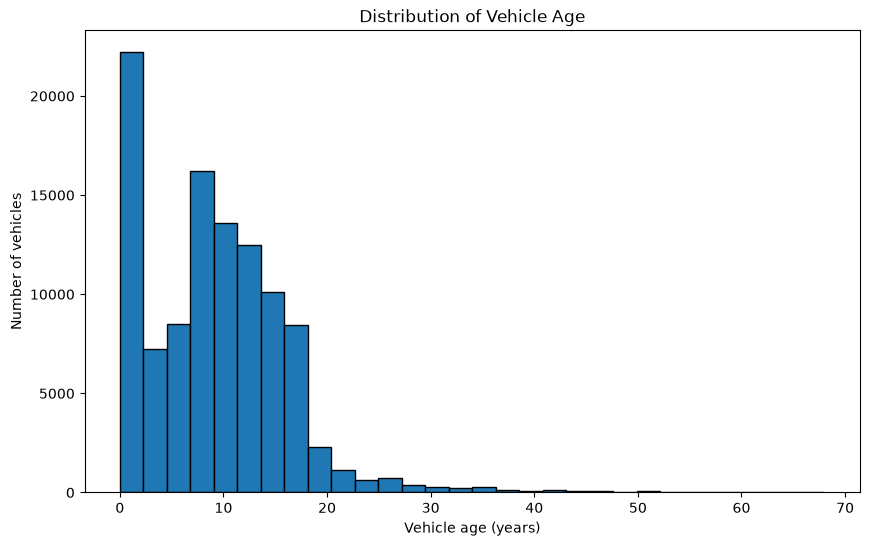

In [58]:
plt.figure(figsize=(10, 6))
plt.hist(vehicle_age, bins=30, edgecolor="black")
plt.xlabel("Vehicle age (years)")
plt.ylabel("Number of vehicles")
plt.title("Distribution of Vehicle Age")
plt.show()

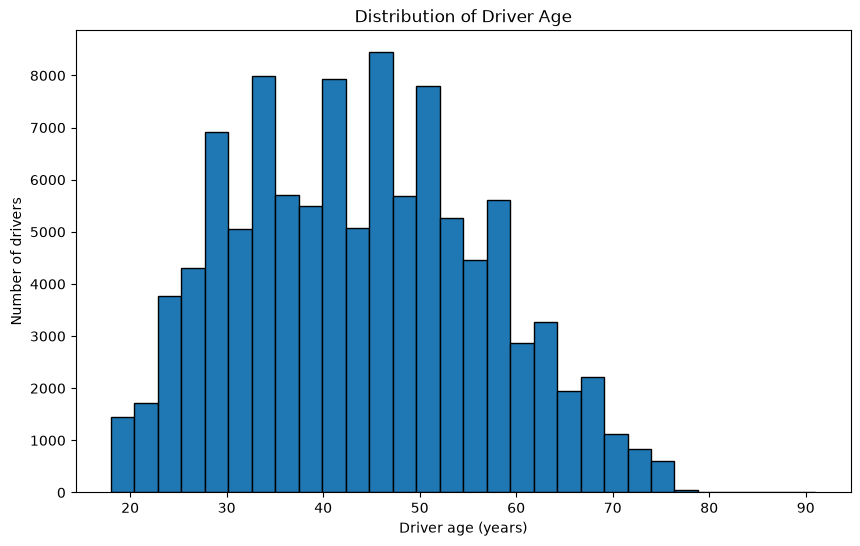

In [59]:
# Show the distribution of driver ages using a histogram
plt.figure(figsize=(10, 6))
plt.hist(driver_age, bins=30, edgecolor="black")
plt.xlabel("Driver age (years)")
plt.ylabel("Number of drivers")
plt.title("Distribution of Driver Age")
plt.show()

In [60]:
# Show the number of insurance claims per record
df["N_claims_year"].value_counts().sort_index()

N_claims_year
0     85909
1      9539
2      4961
3      2435
4      1190
5       609
6       318
7       227
8       136
9        82
10       61
11       24
12       18
13       18
14       10
15        8
16        2
17        3
18        2
19        1
21        1
25        1
Name: count, dtype: int64

In [61]:
# Calculate basic statistics for the number of insurance claims
df["N_claims_year"].describe()

count    105555.000000
mean          0.394695
std           1.105018
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          25.000000
Name: N_claims_year, dtype: float64

In [62]:
# Group drivers by age to compare insurance claims
age_groups = pd.cut(
    driver_age,
    bins=[17, 24, 34, 44, 54, 64, float("inf")],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
)

# Calculate the average number of claims for each age group
claims_by_age = df.groupby(age_groups, observed=True)["N_claims_year"].agg(
    ["count", "mean"]
)

claims_by_age

,count,mean
18-24,5483,0.338318
25-34,22922,0.392636
35-44,26978,0.405367
45-54,27200,0.435147
55-64,16199,0.366319
65+,6773,0.310202


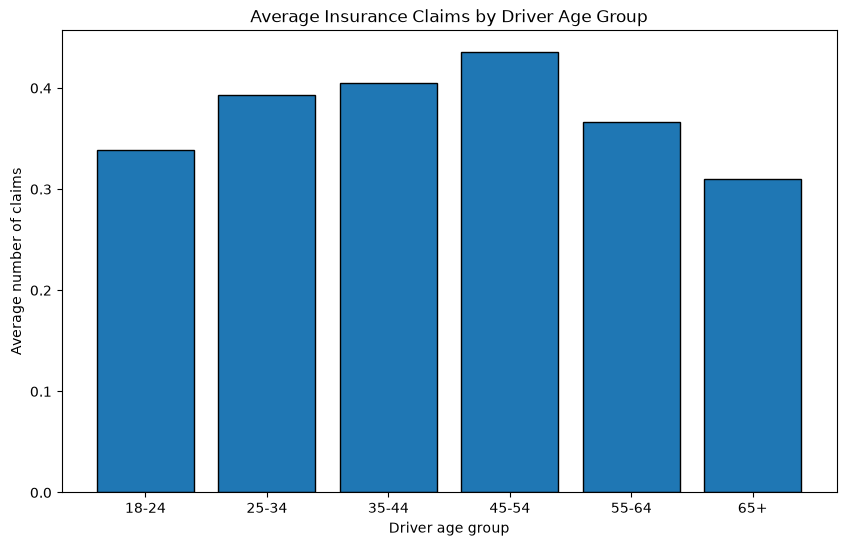

In [63]:
# Compare the average number of insurance claims across driver age groups
plt.figure(figsize=(10, 6))
plt.bar(claims_by_age.index, claims_by_age["mean"], edgecolor="black")
plt.xlabel("Driver age group")
plt.ylabel("Average number of claims")
plt.title("Average Insurance Claims by Driver Age Group")
plt.show()


In [64]:
# Group vehicles by age and calculate the average number of claims
vehicle_age_groups = pd.cut(
    vehicle_age,
    bins=[-1, 2, 5, 10, 15, 20, float("inf")],
    labels=["0-2", "3-5", "6-10", "11-15", "16-20", "21+"]
)

claims_by_vehicle_age = df.groupby(
    vehicle_age_groups, observed=True
)["N_claims_year"].agg(["count", "mean"])

claims_by_vehicle_age

,count,mean
0-2,22195,0.275467
3-5,11314,0.343910
6-10,27467,0.412240
11-15,29370,0.474838
16-20,10760,0.473978
21+,4449,0.289503


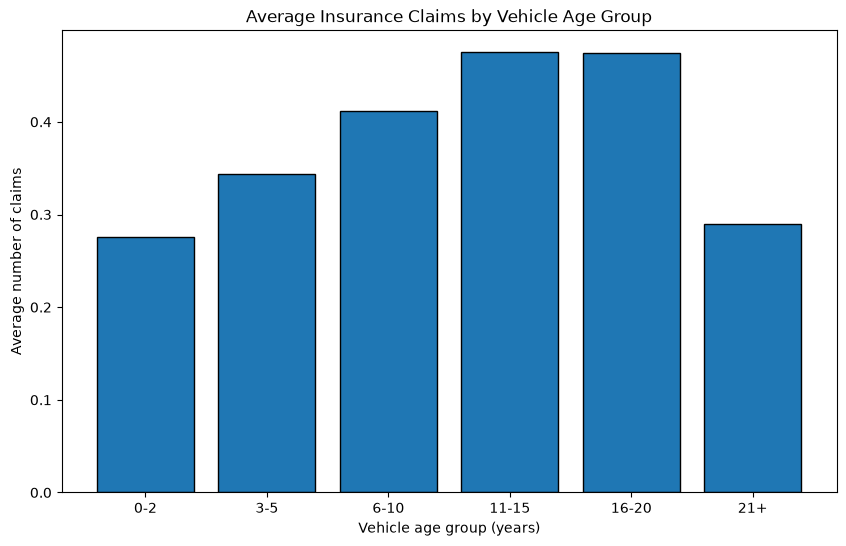

In [65]:
# Compare the average number of insurance claims across vehicle age groups
plt.figure(figsize=(10, 6))
plt.bar(claims_by_vehicle_age.index, claims_by_vehicle_age["mean"], edgecolor="black")
plt.xlabel("Vehicle age group (years)")
plt.ylabel("Average number of claims")
plt.title("Average Insurance Claims by Vehicle Age Group")
plt.show()

In [66]:
# Calculate basic statistics for the annual cost of insurance claims
df["Cost_claims_year"].describe()

count    105555.000000
mean        153.557305
std        1477.112362
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      260853.240000
Name: Cost_claims_year, dtype: float64

In [67]:
# Calculate the average cost per insurance claim
total_claim_cost = df["Cost_claims_year"].sum()
total_claims = df["N_claims_year"].sum()

average_claim_severity = total_claim_cost / total_claims

print("Total claim cost:", round(total_claim_cost, 2))
print("Total number of claims:", total_claims)
print("Average claim severity:", round(average_claim_severity, 2))

Total claim cost: 16208741.37
Total number of claims: 41662
Average claim severity: 389.05


In [68]:
# Calculate the average claim cost for each driver age group
loss_by_age = df.groupby(age_groups, observed=True)["Cost_claims_year"].agg(
    ["count", "mean"]
)

loss_by_age

,count,mean
18-24,5483,160.185174
25-34,22922,178.193106
35-44,26978,157.110807
45-54,27200,150.419891
55-64,16199,129.312905
65+,6773,121.247242


In [69]:
# Calculate the average cost per claim for each driver age group
severity_by_age = df.groupby(age_groups, observed=True).agg(
    total_claims=("N_claims_year", "sum"),
    total_cost=("Cost_claims_year", "sum")
)

severity_by_age["claim_severity"] = (
    severity_by_age["total_cost"] / severity_by_age["total_claims"]
)

severity_by_age

,total_claims,total_cost,claim_severity
18-24,1855,878295.31,473.474561
25-34,9000,4084542.37,453.838041
35-44,10936,4238535.35,387.576385
45-54,11836,4091421.03,345.675991
55-64,5934,2094739.74,353.006360
65+,2101,821207.57,390.865098


In [70]:
# Calculate the average claim cost for each vehicle age group
loss_by_vehicle_age = df.groupby(
    vehicle_age_groups, observed=True
)["Cost_claims_year"].agg(["count", "mean"])

loss_by_vehicle_age

,count,mean
0-2,22195,146.133688
3-5,11314,131.481466
6-10,27467,155.211266
11-15,29370,174.935030
16-20,10760,157.299055
21+,4449,86.346449


In [71]:
# Calculate the average cost per claim for each vehicle age group
severity_by_vehicle_age = df.groupby(
    vehicle_age_groups, observed=True
).agg(
    total_claims=("N_claims_year", "sum"),
    total_cost=("Cost_claims_year", "sum")
)

severity_by_vehicle_age["claim_severity"] = (
    severity_by_vehicle_age["total_cost"]
    / severity_by_vehicle_age["total_claims"]
)

severity_by_vehicle_age

,total_claims,total_cost,claim_severity
0-2,6114,3243437.20,530.493490
3-5,3891,1487581.31,382.313367
6-10,11323,4263187.85,376.506920
11-15,13946,5137841.83,368.409711
16-20,5100,1692537.83,331.870163
21+,1288,384155.35,298.257259


In [72]:
# Inspect contract and renewal dates to understand the insurance period
df[
    ["Date_start_contract", "Date_last_renewal", "Date_next_renewal"]
].head(10)

,Date_start_contract,Date_last_renewal,Date_next_renewal
0,05/11/2015,05/11/2015,05/11/2016
1,05/11/2015,05/11/2016,05/11/2017
2,05/11/2015,05/11/2017,05/11/2018
3,05/11/2015,05/11/2018,05/11/2019
4,26/09/2017,26/09/2017,26/09/2018
5,26/09/2017,26/09/2018,26/09/2019
6,29/11/2013,29/11/2015,29/11/2016
7,29/11/2013,29/11/2016,29/11/2017
8,29/11/2013,29/11/2017,29/11/2018
9,29/11/2013,29/11/2018,29/11/2019


In [73]:
# Calculate the duration between consecutive contract renewals
last_renewal = pd.to_datetime(
    df["Date_last_renewal"], format="%d/%m/%Y"
)

next_renewal = pd.to_datetime(
    df["Date_next_renewal"], format="%d/%m/%Y"
)

renewal_duration = (next_renewal - last_renewal).dt.days

renewal_duration.value_counts().sort_index()

365    96264
366     9291
Name: count, dtype: int64

In [74]:
# Check how many insurance records are marked as lapsed
df["Lapse"].value_counts(dropna=False)

Lapse
0    84007
1    20008
2     1285
3      199
4       45
5        7
6        2
7        2
Name: count, dtype: int64

In [76]:
# Compare lapse values with the presence of a lapse date
pd.crosstab(
    df["Lapse"],
    df["Date_lapse"].notna(),
    rownames=["Lapse"],
    colnames=["Has lapse date"]
)

Has lapse date,False,True
Lapse,,
0,68032,15975
1,2193,17815
2,141,1144
3,31,168
4,10,35
5,1,6
6,0,2
7,0,2


## Probability Analysis of Insurance Claims

In [78]:
# Calculate the probability of having at least one insurance claim
total_records = len(df)
records_with_claims = (df["N_claims_year"] > 0).sum()

claim_probability = records_with_claims / total_records

print(f"Total records: {total_records}")
print(f"Records with at least one claim: {records_with_claims}")
print(f"Probability of at least one claim: {claim_probability:.4f}")
print(f"Probability as percentage: {claim_probability:.2%}")

Total records: 105555
Records with at least one claim: 19646
Probability of at least one claim: 0.1861
Probability as percentage: 18.61%


### Probability of at Least One Insurance Claim

The probability of having at least one insurance claim is calculated as:

$$
P(N \geq 1) = \frac{\text{Records with at least one claim}}{\text{Total records}}
$$

Using the dataset:

$$
P(N \geq 1) = \frac{19646}{105555} \approx 0.1861 = 18.61\%
$$

This means that approximately 18.61% of insurance records contain at least one claim.

This probability is different from the average number of claims per record because some records contain multiple

In [79]:
# Calculate the probability of at least one claim for each driver age group
claim_probability_by_age = (
    (df["N_claims_year"] > 0)
    .groupby(age_groups, observed=True)
    .mean()
    * 100
)

claim_probability_by_age

18-24    17.672807
25-34    19.182445
35-44    19.119282
45-54    19.264706
55-64    17.408482
65+      15.679906
Name: N_claims_year, dtype: float64

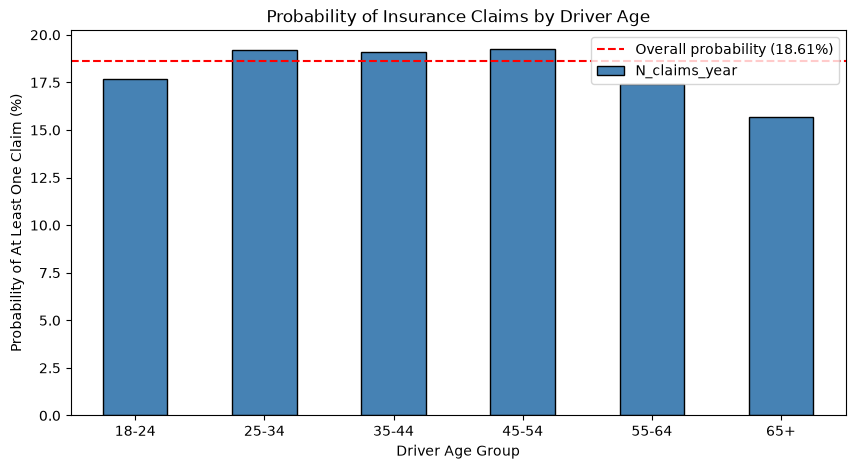

In [80]:
# Visualize claim probability by driver age group
plt.figure(figsize=(10, 5))

claim_probability_by_age.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.axhline(
    y=claim_probability * 100,
    color="red",
    linestyle="--",
    label="Overall probability (18.61%)"
)

plt.title("Probability of Insurance Claims by Driver Age")
plt.xlabel("Driver Age Group")
plt.ylabel("Probability of At Least One Claim (%)")
plt.xticks(rotation=0)
plt.legend()

In [81]:
# Calculate average claim costs for combinations of driver and vehicle age
risk_matrix = df.groupby(
    [age_groups, vehicle_age_groups],
    observed=True
)["Cost_claims_year"].mean().unstack()

risk_matrix.round(2)

,0-2,3-5,6-10,11-15,16-20,21+
18-24,171.39,74.49,148.79,185.35,233.10,158.07
25-34,160.49,130.30,204.03,190.93,193.74,131.11
35-44,128.53,149.36,150.37,194.88,147.33,84.76
45-54,150.42,143.30,146.25,162.16,169.43,71.97
55-64,125.52,99.11,125.97,158.13,132.74,67.08
65+,144.76,154.78,95.76,133.23,99.68,104.43
